In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


In [16]:
num_classes = 10

x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
input_shape = (28, 28, 1)

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255.0
x_test /= 255.0

y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print("Processed training data shape:", x_train.shape)
print("Processed training labels shape:", y_train.shape)
print("Input shape:", input_shape)
print("Number of classes:", num_classes)

Processed training data shape: (60000, 28, 28, 1)
Processed training labels shape: (60000, 10)
Input shape: (28, 28, 1)
Number of classes: 10


In [17]:
batch_size = 128
epochs = 10

model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=input_shape),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,380,938 (9.08 MB)

 Trainable params: 2,380,938 (9.08 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(x_test, y_test)
)

model.save('mnist_model.h5')
print("Model saved as mnist_model.h5")

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.8750 - loss: 0.3975 - val_accuracy: 0.9843 - val_loss: 0.0514
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.8750 - loss: 0.3975 - val_accuracy: 0.9843 - val_loss: 0.0514
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9799 - loss: 0.0665 - val_accuracy: 0.9898 - val_loss: 0.0331
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9799 - loss: 0.0665 - val_accuracy: 0.9898 - val_loss: 0.0331
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.9843 - loss: 0.0472 - val_accuracy: 0.9897 - val_loss: 0.0291
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.9843 - loss: 0.0472 - val_accuracy: 0.9897 - val_loss: 0.0291
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9882 - loss: 0.0361 - val_accuracy: 0.9905 - val_loss: 0.0275
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9882 - loss: 0.0361 - 

Model saved as mnist_model.h5


Test loss: 0.0251
Test accuracy: 0.9921


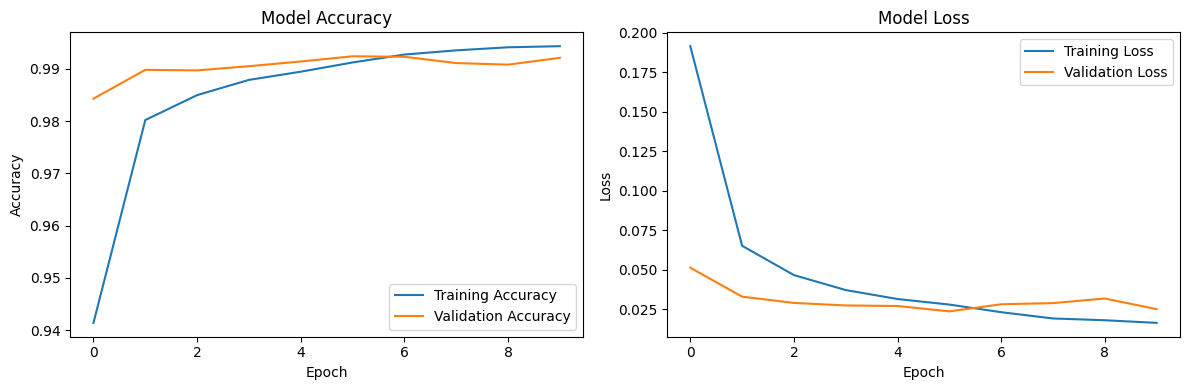

In [19]:
score = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {score[0]:.4f}")
print(f"Test accuracy: {score[1]:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
import tkinter as tk
from tkinter import messagebox
from PIL import Image, ImageDraw
import numpy as np
import cv2
import warnings

warnings.filterwarnings('ignore')

try:
    loaded_model = keras.models.load_model('mnist_model.h5')
    print("Model loaded successfully")
except:
    print("Model file not found. Please train and save the model first.")
    loaded_model = None

def predict_single_digit(img_array):
    if loaded_model is None:
        return None, None
    
    img_array = img_array.reshape(1, 28, 28, 1)
    img_array = img_array.astype('float32') / 255.0
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        prediction = loaded_model.predict(img_array, verbose=0)
    
    digit = np.argmax(prediction)
    confidence = np.max(prediction)
    
    return digit, confidence

def segment_digits(image):
    img_array = np.array(image)
    img_array = 255 - img_array
    
    if np.max(img_array) == 0:
        return []
    
    kernel = np.ones((3,3), np.uint8)
    img_array = cv2.morphologyEx(img_array, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(img_array, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    digit_regions = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        
        if w > 10 and h > 10 and w < 150 and h < 150:
            margin = 10
            x = max(0, x - margin)
            y = max(0, y - margin)
            w = min(image.width - x, w + 2 * margin)
            h = min(image.height - y, h + 2 * margin)
            
            digit_regions.append((x, y, w, h))
    
    digit_regions.sort(key=lambda region: region[0])
    
    digit_images = []
    for x, y, w, h in digit_regions:
        digit_img = image.crop((x, y, x + w, y + h))
        
        aspect_ratio = max(w, h)
        square_img = Image.new('L', (aspect_ratio, aspect_ratio), 255)
        paste_x = (aspect_ratio - w) // 2
        paste_y = (aspect_ratio - h) // 2
        square_img.paste(digit_img, (paste_x, paste_y))
        
        digit_28x28 = square_img.resize((28, 28), Image.Resampling.LANCZOS)
        digit_images.append(digit_28x28)
    
    return digit_images

def predict_multiple_digits(image):
    digit_images = segment_digits(image)
    
    if not digit_images:
        return None, []
    
    predictions = []
    for digit_img in digit_images:
        img_array = np.array(digit_img)
        img_array = 255 - img_array
        digit, confidence = predict_single_digit(img_array)
        if digit is not None:
            predictions.append((digit, confidence))
    
    if predictions:
        final_number = ''.join([str(pred[0]) for pred in predictions])
        return final_number, predictions
    
    return None, []

class MultiDigitRecognitionApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Multi-Digit Handwritten Recognition")
        self.root.geometry("600x700")
        self.root.configure(bg='#f0f0f0')
        
        title_label = tk.Label(root, text="Multi-Digit Recognition System", 
                              font=('Arial', 18, 'bold'), bg='#f0f0f0', fg='#333')
        title_label.pack(pady=10)
        
        instruction_label = tk.Label(root, text="Draw multiple digits with some spacing between them", 
                                   font=('Arial', 11), bg='#f0f0f0', fg='#666')
        instruction_label.pack(pady=5)
        
        canvas_frame = tk.Frame(root, bg='#f0f0f0')
        canvas_frame.pack(pady=10)
        
        self.canvas = tk.Canvas(canvas_frame, width=500, height=150, bg='white', 
                               bd=3, relief='solid', cursor='cross')
        self.canvas.pack()
        
        self.result_frame = tk.Frame(root, bg='#f0f0f0')
        self.result_frame.pack(pady=20)
        
        self.main_result_label = tk.Label(self.result_frame, text="Draw digits and click Predict", 
                                         font=('Arial', 20, 'bold'), fg='blue', bg='#f0f0f0')
        self.main_result_label.pack(pady=10)
        
        self.details_label = tk.Label(self.result_frame, text="", 
                                    font=('Arial', 12), fg='#666', bg='#f0f0f0')
        self.details_label.pack(pady=5)
        
        button_frame = tk.Frame(root, bg='#f0f0f0')
        button_frame.pack(pady=20)
        
        self.predict_btn = tk.Button(button_frame, text="Predict Number", 
                                   command=self.predict_digits, 
                                   bg='#4CAF50', fg='white', font=('Arial', 14, 'bold'),
                                   padx=20, pady=10)
        self.predict_btn.pack(side=tk.LEFT, padx=10)
        
        self.single_digit_btn = tk.Button(button_frame, text="Single Digit Mode", 
                                        command=self.predict_single, 
                                        bg='#2196F3', fg='white', font=('Arial', 14, 'bold'),
                                        padx=20, pady=10)
        self.single_digit_btn.pack(side=tk.LEFT, padx=10)
        
        self.clear_btn = tk.Button(button_frame, text="Clear Canvas", 
                                 command=self.clear_canvas, 
                                 bg='#f44336', fg='white', font=('Arial', 14, 'bold'),
                                 padx=20, pady=10)
        self.clear_btn.pack(side=tk.LEFT, padx=10)
        
        mode_frame = tk.Frame(root, bg='#f0f0f0')
        mode_frame.pack(pady=10)
        
        self.mode_var = tk.StringVar(value="multi")
        
        self.canvas.bind('<B1-Motion>', self.draw)
        self.canvas.bind('<Button-1>', self.draw)
        
        self.image = Image.new('L', (500, 150), 255)
        self.draw_obj = ImageDraw.Draw(self.image)
        
    def draw(self, event):
        x, y = event.x, event.y
        r = 6
        self.canvas.create_oval(x-r, y-r, x+r, y+r, fill='black', outline='black')
        self.draw_obj.ellipse([x-r, y-r, x+r, y+r], fill=0)
        
    def clear_canvas(self):
        self.canvas.delete('all')
        self.image = Image.new('L', (500, 150), 255)
        self.draw_obj = ImageDraw.Draw(self.image)
        self.main_result_label.config(text="Draw digits and click Predict")
        self.details_label.config(text="")
        
    def predict_digits(self):
        if loaded_model is None:
            messagebox.showerror("Error", "Model not loaded. Please train the model first.")
            return
        
        mode = self.mode_var.get()
        
        if mode == "single":
            self.predict_single()
        else:
            self.predict_multi()
    
    def predict_single(self):
        img = self.image.resize((28, 28), Image.Resampling.LANCZOS)
        img_array = np.array(img)
        img_array = 255 - img_array
        
        digit, confidence = predict_single_digit(img_array)
        
        if digit is not None:
            self.main_result_label.config(text=f"Digit: {digit}")
            self.details_label.config(text=f"Confidence: {confidence:.2%}")
        else:
            self.main_result_label.config(text="Prediction failed")
            self.details_label.config(text="")
    
    def predict_multi(self):
        final_number, predictions = predict_multiple_digits(self.image)
        
        if final_number is not None:
            self.main_result_label.config(text=f"Number: {final_number}")
            
            if len(predictions) > 1:
                details_text = "Individual digits: "
                for i, (digit, conf) in enumerate(predictions):
                    details_text += f"{digit}({conf:.1%}) "
                self.details_label.config(text=details_text)
            else:
                self.details_label.config(text=f"Confidence: {predictions[0][1]:.2%}")
        else:
            self.main_result_label.config(text="No digits detected")
            self.details_label.config(text="Make sure digits are clearly drawn with spacing")

print("Starting Multi-Digit Recognition Application...")

if loaded_model is not None:
    try:
        root = tk.Tk()
        app = MultiDigitRecognitionApp(root)
        print("Application started successfully. Close the window to stop.")
        root.mainloop()
    except Exception as e:
        print(f"Error starting application: {e}")
        print("Make sure all dependencies are installed properly.")
else:
    print("Cannot start GUI without trained model. Please run the training cells first.")

Model loaded successfully
Starting Multi-Digit Recognition Application...
Application started successfully. Close the window to stop.
